## Домашнее задание 3

Кто будет пользоваться сетками для написания кода, тот редиска. Я серьезно. Не надо

In [10]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

### Задача 1

Доделайте определение ускорения свободного падения по видео

**Ход работы**


Для определения ускорения свободного падения маркера воспользуемся самой простой моделью кинематического движения тела в поле гравитации:
$$
\bm{y}(t) = \bm{y}_0 + \bm{v}_0\cdot t + \frac{\bm{a}\cdot t^2}{2}.
$$

Исходя из видео сразу положим $\bm{y}_0 = \bm{0}$, $\bm{v}_0\cdot t = \bm{0}$, $\bm{a} \equiv \bm{g}$. Также спроецируем всё на вертикальную ось, направленную вниз:
$$
y(t) = \frac{g}{2}\cdot t^2.
$$

Таким образом, если получить координаты маркера для какого-то количества кадров, то можно будет построить график $y(t)$. Тогда коэффициент наклона прямой будет равен $\frac{1}{2}\cdot g$.

In [3]:
cam = cv2.VideoCapture("./video/g.mp4")

fps = cam.get(cv2.CAP_PROP_FPS)
frame_count = cam.get(cv2.CAP_PROP_FRAME_COUNT)
time = frame_count / fps

print(f"Количество кадров: {int(frame_count)}")
print(f"Продолжительность: {time:.2f} с")

cam.release()

Количество кадров: 151
Продолжительность: 1.26 с


Теперь найдём последний кадр, где маркер еще держат в руках. Небольшим перебором я остановился на 44 кадре. Теперь можно найти, в какой момент времени $t_0$ начинается падение:
$$
t_0 = \frac{номер\ искомого\ кадра}{количество\ кадров\ в\ видео} \cdot\ продолжительность\ видео = \frac{44}{151} \cdot 1.26\ с = 0.367\ с.
$$

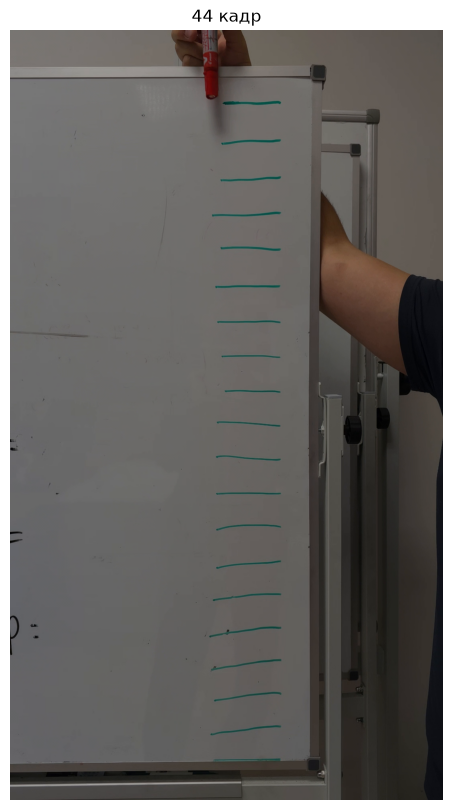

In [4]:
cam = cv2.VideoCapture("./video/g.mp4")
frame_number = 44

cam.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

ret, frame = cam.read()
rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
cam.release()

plt.figure(figsize=(8, 10))
plt.imshow(rgb)
plt.title(f"{frame_number} кадр")
plt.axis("off")
plt.show()

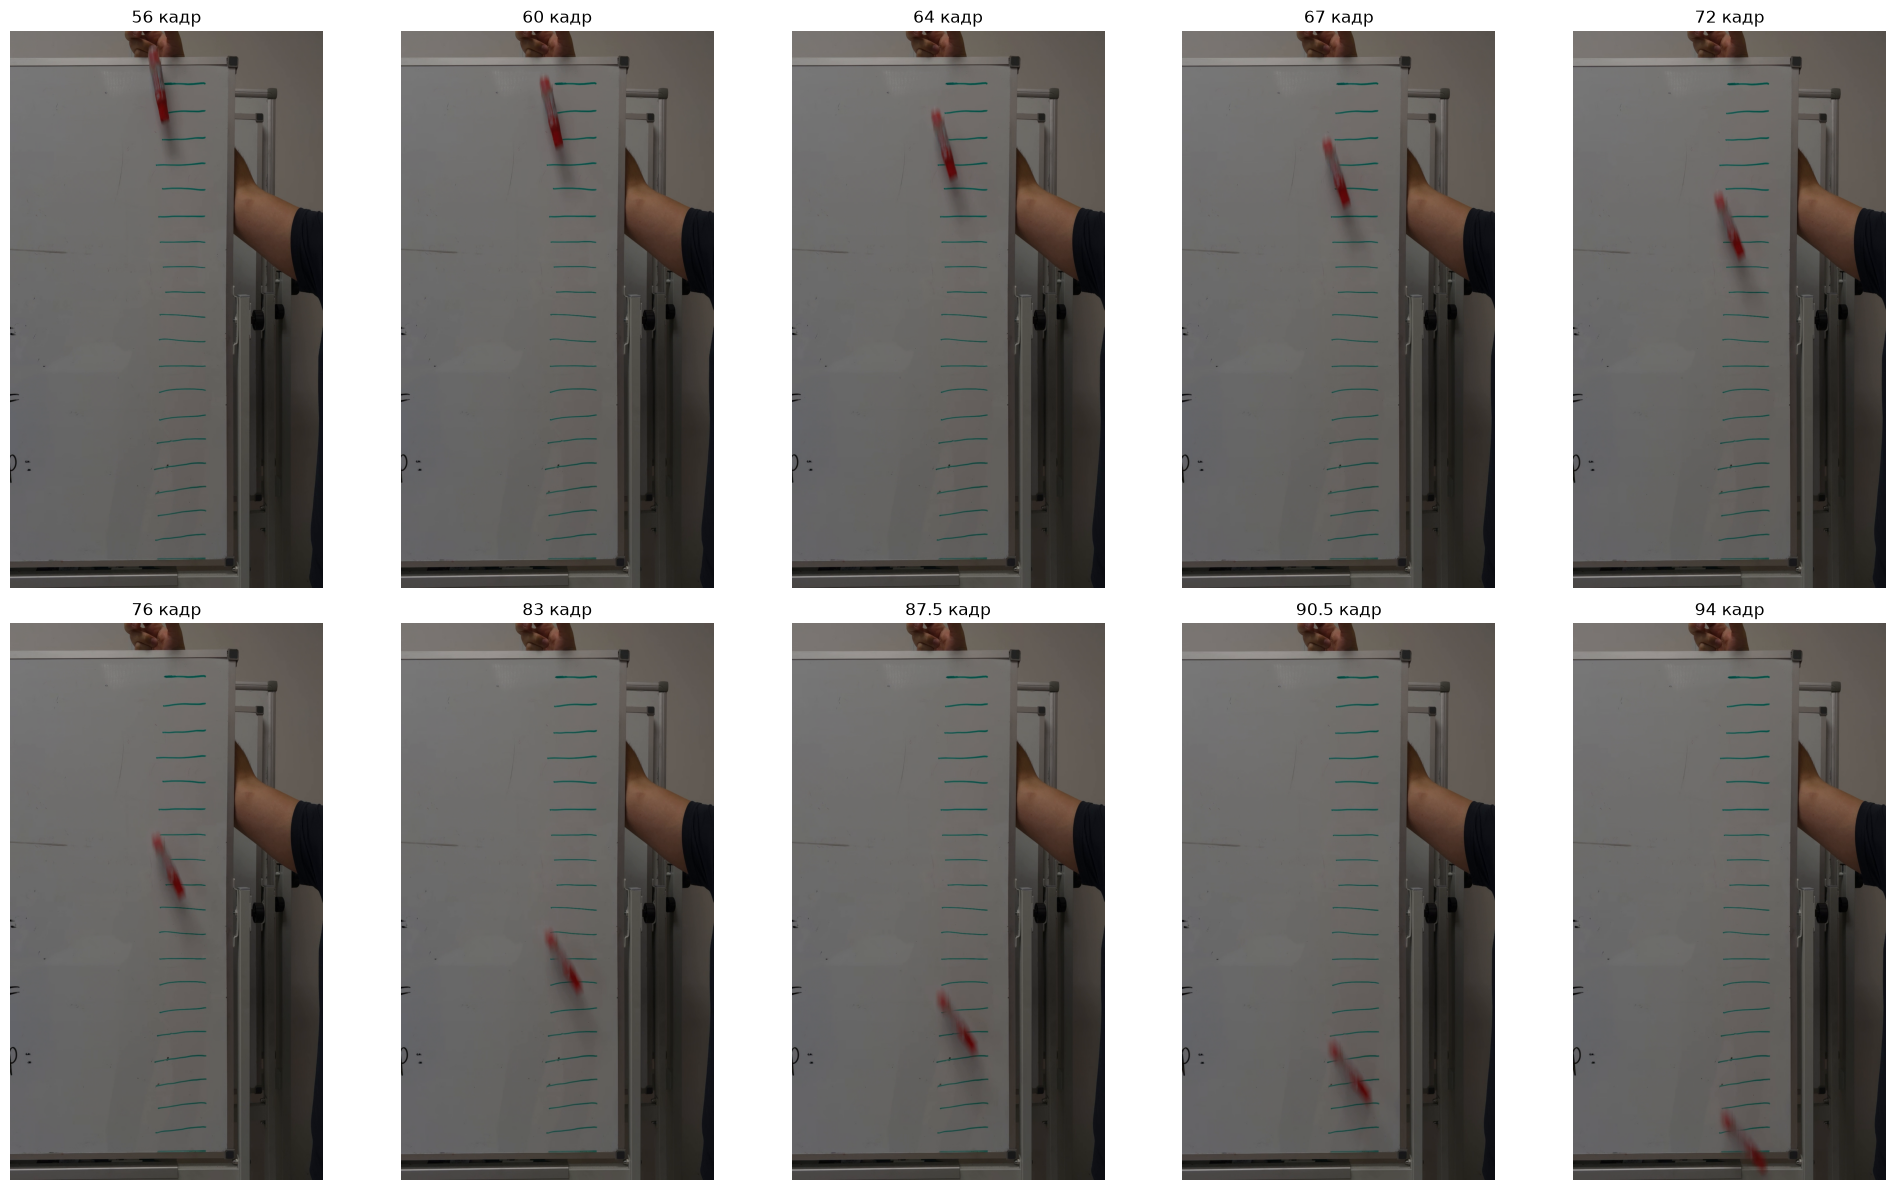

In [5]:
cam = cv2.VideoCapture("./video/g.mp4")

frame_numbers = [56, 60, 64, 67, 72, 76, 83, 87.5, 90.5, 94]

fig, axes = plt.subplots(2, 5, figsize=(20, 12))

for i, frame_number in enumerate(frame_numbers):
    row = i // 5
    col = i % 5

    cam.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ret, frame = cam.read()
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    axes[row, col].imshow(rgb)
    axes[row, col].set_title(f"{frame_number} кадр")
    axes[row, col].axis("off")

cam.release()

plt.tight_layout()
plt.show()

---

В силу того, что движение маркера не было строго поступательным, но содержало и вращательную компоненту, я следил именного за геометрическим центром, который с хорошей точностью совпадает с центром масс маркера, относительно которого и происходит вращение, а значит для ЦМ можно теперь не учитывать вертикальное укорочение маркера по мере его вращения.

Некоторые моменты пересечения отметок находятся между соседними кадрами. Поэтому я использую дробные номера кадров, полученные путём визуальной оценки положения ЦМ.

Время падения будем считать следующим образом:
$$
t(N) = \frac{N-44}{\text{FPS}} = \frac{N-44}{119.52}.
$$

Исходя из полученных кадров, можем составить таблицу:

| № измерения | Пройденная риска | Кадр \(N\) | y, м | $t_{\text{пад}}$, с |
|---|---|---|---|---|
| 0 | 0 | 44 | 0.00 | 0.0000 |
| 1 | 1 | 56 | 0.05 | 0.1004 |
| 2 | 2 | 60 | 0.10 | 0.1339 |
| 3 | 3 | 64 | 0.15 | 0.1673 |
| 4 | 4 | 67 | 0.20 | 0.1924 |
| 5 | 6 | 72 | 0.30 | 0.2343 |
| 6 | 8 | 76 | 0.40 | 0.2677 |
| 7 | 11 | 83 | 0.55 | 0.3263 |
| 8 | 14 | 87.5 | 0.70 | 0.3639 |
| 9 | 16 | 90.5 | 0.80 | 0.3891 |
| 10 | 19 | 94 | 0.95 | 0.4183 |

---

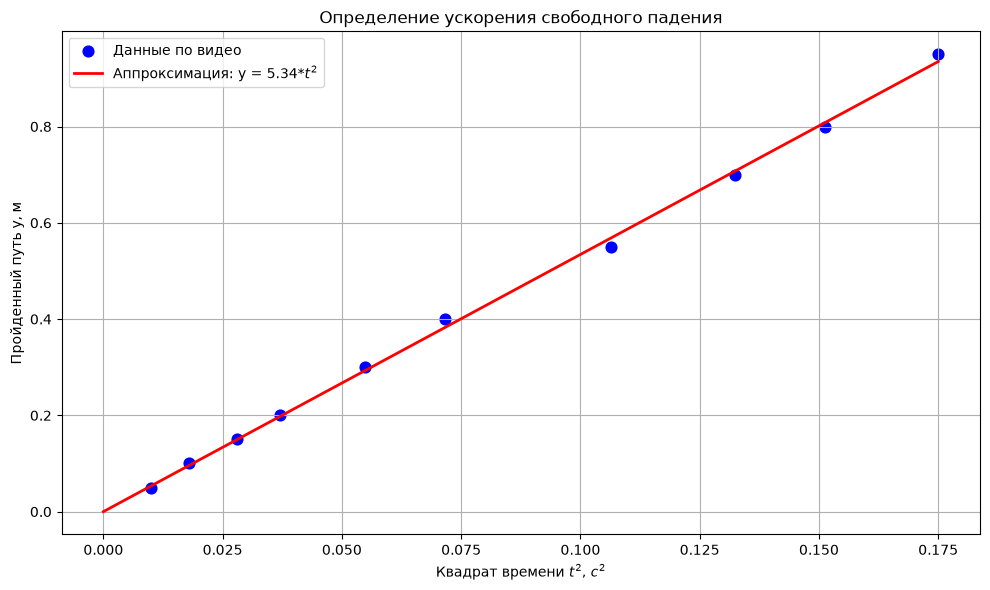

Коэффициент наклона = 5.34
Ускорение свободного падения g = 10.69 м/с²
Относительная погрешность = 8.92%


In [6]:
g_th = 9.81
fps = 119.52
start_frame = 44
marks = np.array([1, 2, 3, 4, 6, 8, 11, 14, 16, 19])
frames = np.array([56, 60, 64, 67, 72, 76, 83, 87.5, 90.5, 94])


y = marks * 0.05
t = (frames - start_frame) / fps

# Эксперимент
t_sqr = t**2
k = np.sum(t_sqr * y) / np.sum(t_sqr**2)
g_prac = 2 * k
plt.figure(figsize=(10, 6))
plt.scatter(t_sqr, y, color="blue", s=60, label="Данные по видео")


# Аппроксимация прямой
err = abs(g_prac - g_th) / g_th * 100
t_sqr_approx = np.linspace(0, max(t_sqr), 200)
y_approx = k * t_sqr_approx
plt.plot(
    t_sqr_approx,
    y_approx,
    color="red",
    linewidth=2,
    label=f"Аппроксимация: y = {k:.2f}*$t^2$",
)

plt.title("Определение ускорения свободного падения")
plt.xlabel("Квадрат времени $t^2$, $с^2$")
plt.ylabel("Пройденный путь y, м")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Вывод результатов
print(f"Коэффициент наклона = {k:.2f}")
print(f"Ускорение свободного падения g = {g_prac:.2f} м/с²")
print(f"Относительная погрешность = {err:.2f}%")

---

Посчитаем погрешность $\sigma_g$ в этом эксперименте. Имеем:
$$
g \equiv g(y, t) = \frac{2\cdot y}{t^2}. 
$$

Тогда по определению:
$$
\sigma_g = \sqrt{\left(\frac{\partial g(y, t)}{\partial y}\right)^2 \cdot \sigma_y^2 + \left(\frac{\partial g(y, t)}{\partial t}\right)^2 \cdot \sigma_t^2} = \sqrt{\left(\frac{2}{t^2}\right)^2 \cdot \sigma_y^2 + \left(\frac{-4\cdot y}{t^3}\right)^2 \cdot \sigma_t^2} = 
$$

$$
= \sqrt{\left(\frac{2}{t^2}\right)^2 \cdot \sigma_y^2 + \left(\frac{4\cdot y}{t^3}\right)^2 \cdot \sigma_t^2} = \sqrt{\left(\frac{2\cdot y}{t^2}\right)^2 \cdot \frac{1}{y^2}\cdot \sigma_y^2 + \left(\frac{2\cdot y}{t^2}\cdot\frac{2}{t}\right)^2 \cdot \sigma_t^2} = g\cdot \sqrt{\frac{\sigma_y^2}{y^2} + 4\cdot\frac{\sigma_t^2}{t^2}}.
$$

В проведённом эксперименте погрешности я определяю примерно так:
$$
\sigma_y=1\text{ см}=0.01\text{ м}.
$$

Погрешность определения момента пересечения риски составляет $\pm$ 2 кадра. При $\text{FPS}=119.52\ \frac{кадров}{c}$ получаем:
$$
\sigma_t=\frac{2}{119.52}\text{ с}\approx0.01673\text{ с}.
$$

Для оценки рассмотрим последнее измерение, которому соответствует наибольшее пройденное расстояние ($y=0.95\text{ м}$):
$$
t=\frac{94-44}{119.52}\text{ с}\approx0.41834\text{ с}.
$$

Тогда для погрешности имеем:
$$
\sigma_g=10.69\cdot\sqrt{\frac{0.01^2}{0.95^2} + 4\cdot\frac{0.01673^2}{0.41834^2}} \text{ м/с}^2 \approx 0.86\text{ м/с}^2.
$$

Итак, в результате по последнему измерению получаем:
$$
\boxed{g = (10.69 \pm 0.86) \text{ м/с}^2}.
$$

---

### Задача 2

Возьмите демку с вычитанием фона и сделайте на ее основе детектирование человека на уницикле. Результат должен выглядеть как видео, на котором bounding box-ом обведен едущий человек вместе со своим транспортным средством. Видео нужно загрузить в классрум.

Рекомендуемые шаги следующие:
- зацикливаем вопроизведение видео (if успех считывания == False, cam.release() и открытие заново)
- поддерживаем усредненный HSV кадр
- вычитаем текущий
- внимательно смотрим на разность, думаем, какие каналы использовать для детектирования
- применяем inRange
- обрабатываем маску морфологией
- фильтруем связные компоненты
- ...постпроцессинг... (творческая задача)
- рисуем bbox и радуемся

In [ ]:
path = "./video/unicycle.mp4"
cam = cv2.VideoCapture(path)

ret, frame = cam.read()
avg = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

while True:
    ret, frame = cam.read()

    if not ret:
        cam.release()
        cam = cv2.VideoCapture(path)

        ret, frame = cam.read()
        avg = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
        continue

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    diff = cv2.absdiff(avg, hsv)
    diff_h, diff_s, diff_v = cv2.split(diff)
    avg = cv2.addWeighted(avg, 0.99, hsv, 0.01, 0)

    cv2.imshow("diff H", diff_h)
    cv2.imshow("diff S", diff_s)
    cv2.imshow("diff V", diff_v)

    if cv2.waitKey(30) & 0xFF == ord("q"):
        break

cam.release()
cv2.destroyAllWindows()

Отсюда делаем вывод, что для детектирование наиболее уместно использовать канал `V`.

In [11]:
def get_diff_v(frame, avg):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    diff = cv2.absdiff(avg, hsv)
    diff_v = diff[:, :, 2]
    avg = cv2.addWeighted(avg, 0.99, hsv, 0.01, 0)

    return avg, diff_v


def get_mask(diff_v):
    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (19, 19))

    mask = cv2.inRange(diff_v, 25, 255)
    mask_opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
    mask_opened_closed = cv2.morphologyEx(mask_opened, cv2.MORPH_CLOSE, kernel_close)

    return mask_opened_closed


def filter_mask(mask):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask)

    filtered_mask = np.zeros_like(mask)
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]

        if area > 500:
            filtered_mask[labels == i] = 255

    return filtered_mask


def get_bbox(mask):
    points = cv2.findNonZero(mask)
    x, y, w, h = cv2.boundingRect(points)
    return x, y, w, h


path = "./video/unicycle.mp4"
cam = cv2.VideoCapture(path)

ret, frame = cam.read()
avg = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

while True:
    ret, frame = cam.read()

    if not ret:
        cam.release()
        cam = cv2.VideoCapture(path)

        ret, frame = cam.read()
        avg = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
        continue

    avg, diff_v = get_diff_v(frame, avg)

    mask = get_mask(diff_v)
    filtered_mask = filter_mask(mask)

    bbox = get_bbox(filtered_mask)

    x, y, w, h = bbox
    cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # cv2.imshow("mask", mask)
    # cv2.imshow("filtered_mask", filtered_mask)
    cv2.imshow("frame", frame)

    if cv2.waitKey(30) & 0xFF == ord("q"):
        break

cam.release()
cv2.destroyAllWindows()

## Результат

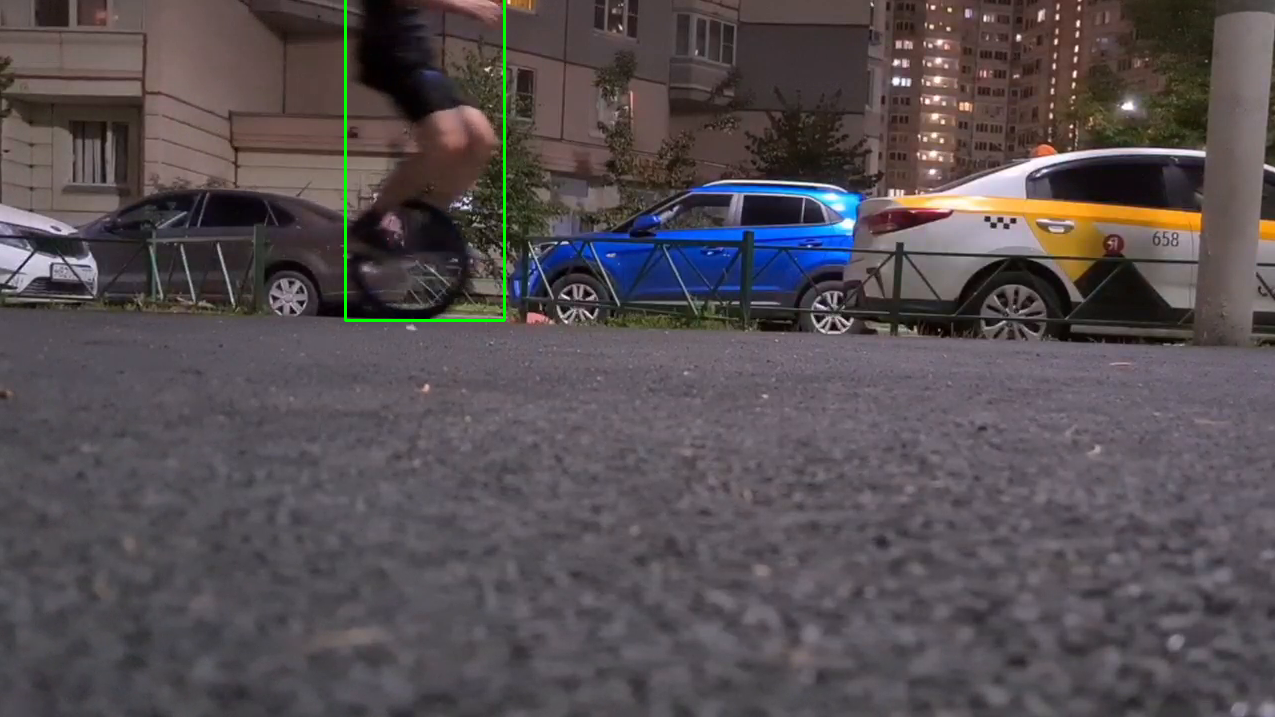